# Diabetes Dataset — Descriptive Analytics: Data Collection Flaws



## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CSV_PATH = "C:/Users/corre/OneDrive/Documents/Flavio - Copy (2)/Harvard/CSCI - E-184/PSET4/diabetes.csv"   # adjust path if needed

df = pd.read_csv(CSV_PATH)

# shared style
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
ZERO_COLOR  = "#d62728"   # red   = the flaw
VALID_COLOR = "#1f77b4"   # blue  = real data
ACCENT      = "#ff7f0e"   # orange = secondary

ZERO_COLS = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']

print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")
df.describe().round(1)

Rows: 768   Columns: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2,0.3
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8,0.5
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0,0.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0,0.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0,0.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0,1.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0,1.0


---
## Fig 1 — Missing data: incorrect zeros per column

A living person cannot have zero glucose, blood pressure, BMI, insulin, or skin thickness. These zeros are not real measurements — they are missing values that were coded as `0` instead of `NaN`. Any standard summary statistic (`mean`, `std`, `corr`) computed on these columns is therefore wrong.

The red bars flag columns where more than 10 % of values are fake — those statistics are the most distorted.


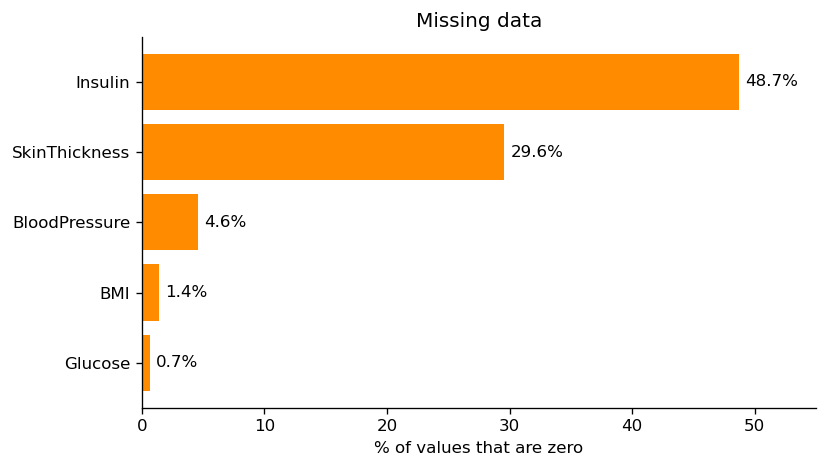

Insulin mean WITH fake zeros    :  79.8
Insulin mean WITHOUT fake zeros : 155.5
-> The zeros understate the true mean by 49%.


In [4]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zpct = {c: (df[c] == 0).mean() * 100 for c in zero_cols}
zser = pd.Series(zpct).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(zser.index, zser.values, color="darkorange")
ax.set_xlabel("% of values that are zero")
ax.set_title("Missing data")
for b, v in zip(bars, zser.values):
    ax.text(v + 0.5, b.get_y()+b.get_height()/2, f"{v:.1f}%", va="center")
ax.set_xlim(0, 55)
plt.tight_layout(); plt.show()

# The concrete damage: what the fake zeros do to a summary statistic
ins_with = df['Insulin'].mean()
ins_without = df.loc[df['Insulin'] > 0, 'Insulin'].mean()
print(f"Insulin mean WITH fake zeros    : {ins_with:5.1f}")
print(f"Insulin mean WITHOUT fake zeros : {ins_without:5.1f}")
print(f"-> The zeros understate the true mean by {(1-ins_with/ins_without)*100:.0f}%.")

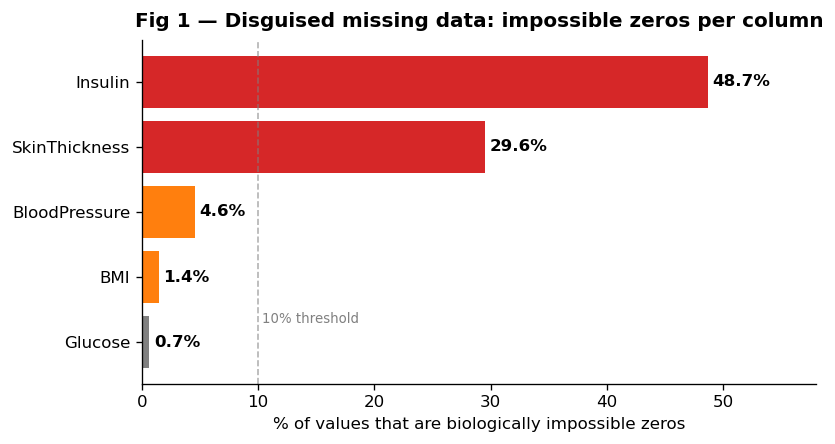

Insulin mean WITH zeros    :   79.8  <- what describe() shows
Insulin mean WITHOUT zeros :  155.5  <- the real number
Inflation: 49% understatement


In [3]:
# Include threshold of 10% and paint values according to breach of threshold
zpct = {c: (df[c] == 0).mean() * 100 for c in ZERO_COLS}
zser = pd.Series(zpct).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.8))
colors = [ZERO_COLOR if v > 10 else ACCENT if v > 1 else 'grey'
          for v in zser.values]
bars = ax.barh(zser.index, zser.values, color=colors)
ax.set_xlabel('% of values that are biologically impossible zeros')
ax.set_title('Fig 1 — Disguised missing data: impossible zeros per column',
             fontweight='bold', pad=8)
for b, v in zip(bars, zser.values):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2,
            f'{v:.1f}%', va='center', fontweight='bold')
ax.axvline(10, ls='--', lw=1, color='grey', alpha=0.6)
ax.text(10.3, 0.3, '10% threshold', color='grey', fontsize=8)
ax.set_xlim(0, 58)
plt.tight_layout(); plt.show()

# Concrete damage to summary statistics
ins_with    = df['Insulin'].mean()
ins_without = df.loc[df['Insulin'] > 0, 'Insulin'].mean()
print(f"Insulin mean WITH zeros    : {ins_with:6.1f}  <- what describe() shows")
print(f"Insulin mean WITHOUT zeros : {ins_without:6.1f}  <- the real number")
print(f"Inflation: {(1 - ins_with/ins_without)*100:.0f}% understatement")

**Reading the chart.** Insulin (48.7%) and SkinThickness (29.6%) are the worst offenders — nearly half and a third of their values are fake. The immediate, concrete damage: the `describe()` mean for Insulin reports **79.8**, but the true mean of recorded values is **155.5** — a 49% understatement caused entirely by zeros that should have been `NaN`.

---
## Fig 2 — Distribution detail
The bar chart above what those zeros look like — the red bar on the far left is a spike of fake data sitting at zero, completely separated from the real clinical range.

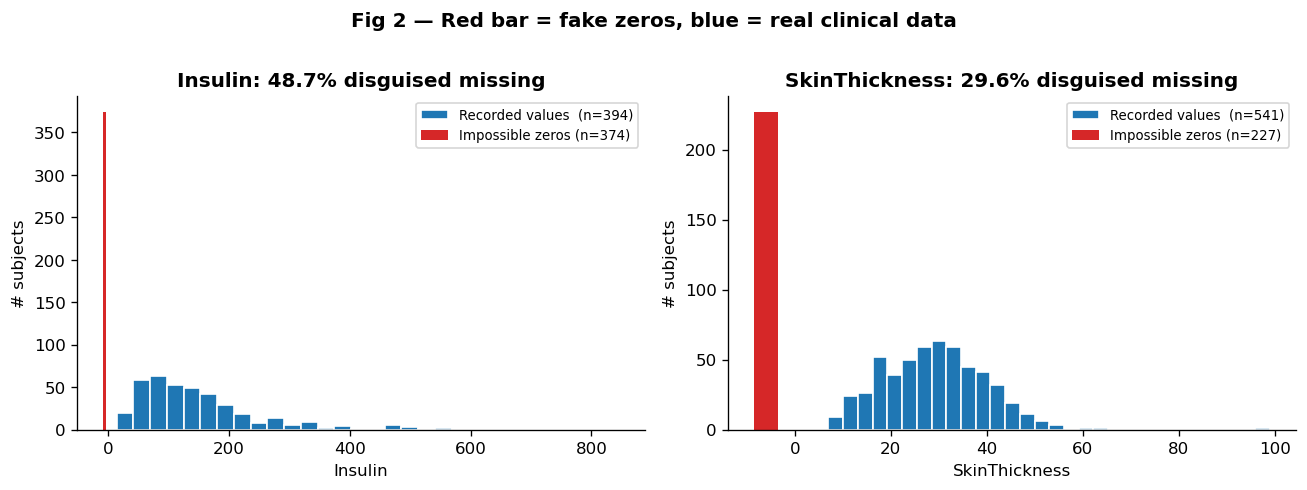

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col in zip(axes, ['Insulin', 'SkinThickness']):
    real  = df.loc[df[col] > 0, col]
    zeros = (df[col] == 0).sum()
    ax.hist(real, bins=30, color=VALID_COLOR, edgecolor='white',
            label=f'Recorded values  (n={len(real)})')
    ax.bar([-6], [zeros], width=5, color=ZERO_COLOR,
           label=f'Impossible zeros (n={zeros})')
    ax.axvline(0, color='white', lw=0)  # visual anchor
    ax.set_xlabel(col)
    ax.set_ylabel('# subjects')
    ax.set_title(f'{col}: {100*zeros/len(df):.1f}% disguised missing',
                 fontweight='bold')
    ax.legend(fontsize=8)

fig.suptitle('Fig 2 — Red bar = fake zeros, blue = real clinical data',
             fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

**Reading the chart.** The gap between the red bar (at 0) and the leftmost blue bin is the visual proof that these zeros are *not* part of the real distribution — no measured patient sits between 0 and ~14 µU/ml for insulin or between 0 and ~7 mm for skin thickness. The gap is the signature of a missing-value code masks as a measurement.

---
## Fig 3 — Outliers across all features

Even after excluding the impossible zeros, the data contains extreme values that suggest measurement error or data-entry problems. Boxplots expose outliers (red dots) column by column. Zeros are set to `NaN` before plotting so they don't dominate the scale.

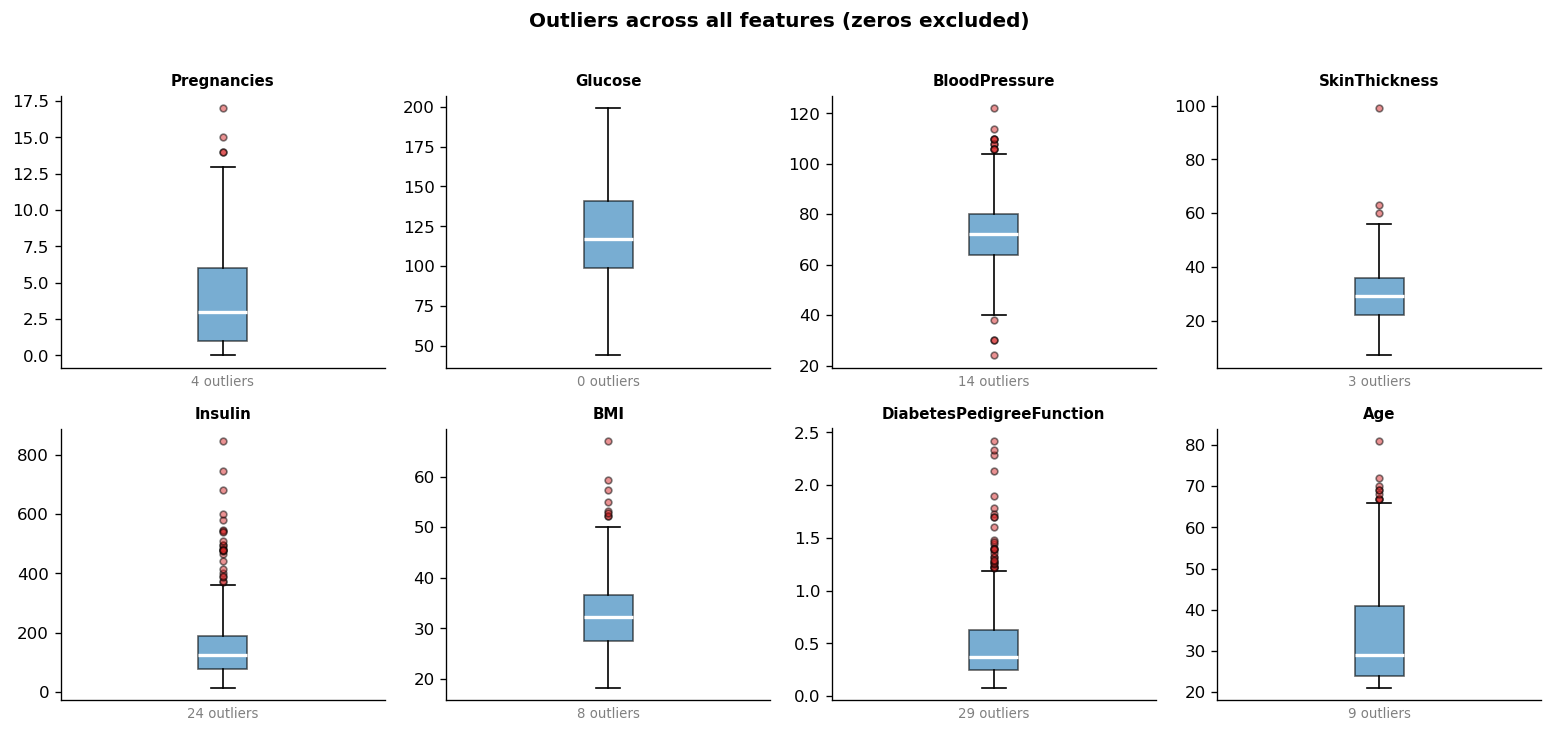

Notable extremes (post zero-removal):
  Insulin max : 846.0 µU/ml  (>600: 3 subjects)
  BMI max     : 67.1 kg/m²   (>50:  8 subjects)
  Pregnancies : max 17  (>10: 34 subjects)
  SkinThick.  : max 99 mm  (>60: 2 subjects)


In [13]:
clean = df.copy()
for c in ZERO_COLS:
    clean.loc[clean[c] == 0, c] = np.nan

features = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
            'Insulin','BMI','DiabetesPedigreeFunction','Age']

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, feat in zip(axes.flat, features):
    data = clean[feat].dropna()
    bp = ax.boxplot(data, patch_artist=True,
                    boxprops=dict(facecolor=VALID_COLOR, alpha=0.6),
                    medianprops=dict(color='white', lw=2),
                    flierprops=dict(marker='o', markerfacecolor=ZERO_COLOR,
                                   markersize=4, alpha=0.5))
    n_out = len([v for f in bp['fliers'] for v in f.get_ydata()])
    ax.set_title(feat, fontweight='bold', fontsize=9)
    ax.set_xticks([])
    ax.set_xlabel(f'{n_out} outliers', fontsize=8, color='grey')

fig.suptitle('Outliers across all features (zeros excluded)',
             fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

# Flag the most extreme values
print("Notable extremes (post zero-removal):")
print(f"  Insulin max : {clean['Insulin'].max()} µU/ml  (>600: {(clean['Insulin']>600).sum()} subjects)")
print(f"  BMI max     : {clean['BMI'].max()} kg/m²   (>50:  {(clean['BMI']>50).sum()} subjects)")
print(f"  Pregnancies : max {int(clean['Pregnancies'].max())}  (>10: {(clean['Pregnancies']>10).sum()} subjects)")
print(f"  SkinThick.  : max {int(clean['SkinThickness'].max())} mm  (>60: {(clean['SkinThickness']>60).sum()} subjects)")

Insulin has the widest range: its maximum is 846 — three subjects exceed 600, which is clinically extreme and (almost certainly) erroneous. BMI reaches 67.1 (8 subjects above 50, when the scale goes up to 30 to 40 for very obese people), which is also very unlikely. Pregnancies reach the number of 17, which is medically possible for a woman to get pregnant this number of times, but flags 34 subjects above 10. 

---
## Fig 4 — Class imbalance

The outcome is 65% negative / 35% positive. That moderate imbalance is enough to let a model fake good performance by simply predicting 'no diabetes' for every subject.

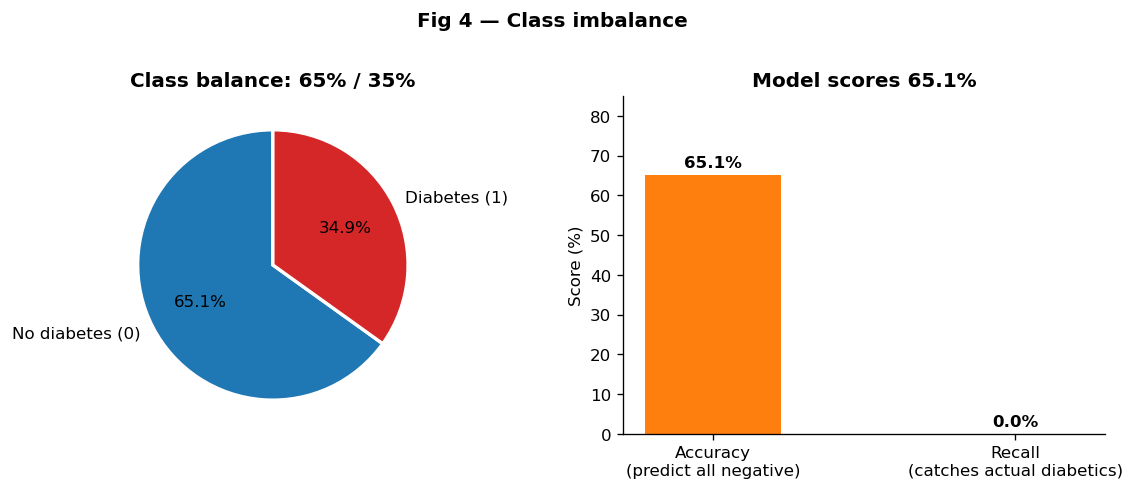

Class counts: {0: 500, 1: 268}
A model predicting 'no diabetes' for everyone:
  Accuracy : 65.1%   <- sounds OK
  Recall   : 0.0%    <- catches zero actual diabetics
Use precision / recall / F1 / AUC instead.


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

counts = df['Outcome'].value_counts().sort_index()
ax1.pie(counts.values,
        labels=['No diabetes (0)', 'Diabetes (1)'],
        autopct='%1.1f%%',
        colors=[VALID_COLOR, ZERO_COLOR],
        startangle=90,
        wedgeprops=dict(edgecolor='white', linewidth=2))
ax1.set_title('Class balance: 65% / 35%', fontweight='bold')

majority_share = counts.max() / counts.sum() * 100
metrics = ['Accuracy\n(predict all negative)', 'Recall\n(catches actual diabetics)']
values  = [majority_share, 0.0]
bars = ax2.bar(metrics, values, color=[ACCENT, ZERO_COLOR], width=0.45)
ax2.set_ylabel('Score (%)')
ax2.set_ylim(0, 85)
ax2.set_title('Model scores 65.1%', fontweight='bold')
for b, v in zip(bars, values):
    ax2.text(b.get_x() + b.get_width() / 2, v + 2,
             f'{v:.1f}%', ha='center', fontweight='bold')

fig.suptitle('Fig 4 — Class imbalance',
             fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

print(f"Class counts: {counts.to_dict()}")
print("A model predicting 'no diabetes' for everyone:")
print(f"  Accuracy : {majority_share:.1f}%   <- sounds OK")
print( "  Recall   : 0.0%    <- catches zero actual diabetics")
print("Use precision / recall / F1 / AUC instead.")

**Reading the chart.** The right panel is the key point: a model that never predicts diabetes scores **65.1% accuracy** — above the threshold many analysts would call 'good' — while catching **0% of actual diabetics**. In a screening context, that model is actively harmful: it gives false reassurance to every patient at risk. Evaluation must use recall-aware metrics, and the decision threshold should be tuned to favour recall over precision.

---
## Fig 5 — Age skew

Age is a major diabetes risk factor — but the cohort is youngest-heavy. The bars show how many subjects fall in each decade; the line shows the diabetes positive rate for each band. Where the data is thinnest, the risk is highest.

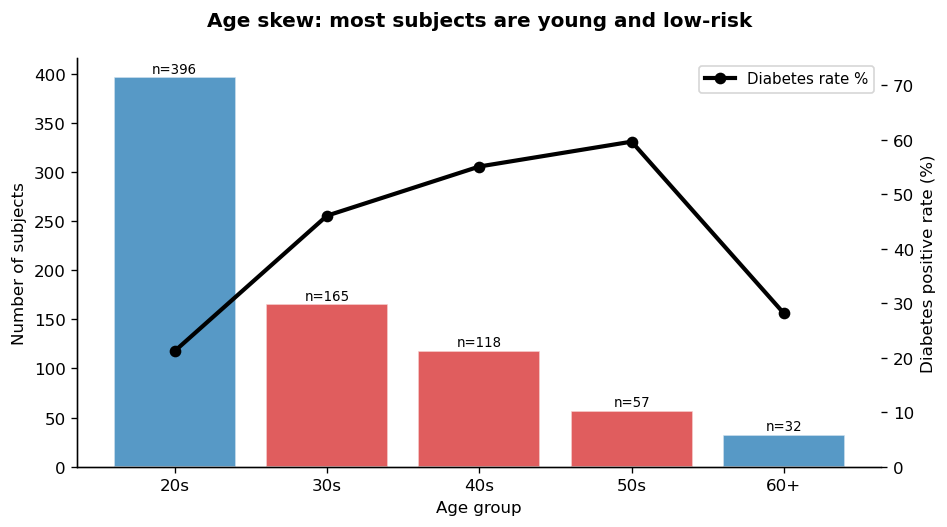

             n   pct  pos_rate
age_group                     
20s        396  51.6      21.2
30s        165  21.5      46.1
40s        118  15.4      55.1
50s         57   7.4      59.6
60+         32   4.2      28.1


In [16]:
bins   = [20, 30, 40, 50, 60, 90]
labels = ['20s', '30s', '40s', '50s', '60+']
df['age_group'] = pd.cut(df['Age'], bins=bins, right=False, labels=labels)

ag = df.groupby('age_group', observed=True).agg(
    n=('Age', 'size'), pr=('Outcome', 'mean'))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
bar_colors = [VALID_COLOR if v < 0.4 else ZERO_COLOR for v in ag['pr']]
bars = ax1.bar(ag.index, ag['n'], color=bar_c
               olors, alpha=0.75, edgecolor='white')
ax1.set_ylabel('Number of subjects')
ax1.set_xlabel('Age group')

ax2 = ax1.twinx()
ax2.plot(ag.index, ag['pr'] * 100, color='black',
         marker='o', linewidth=2.5, label='Diabetes rate %')
ax2.set_ylabel('Diabetes positive rate (%)')
ax2.set_ylim(0, 75)

for i, (idx, row) in enumerate(ag.iterrows()):
    ax1.text(i, row['n'] + 5, f"n={int(row['n'])}",
             ha='center', fontsize=8, color='black')

ax1.set_title('Age skew: most subjects are young and low-risk\n', fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()

print(ag.assign(pct=(ag['n']/len(df)*100).round(1),
                pos_rate=(ag['pr']*100).round(1))[['n','pct','pos_rate']])

Considering the diabetes rate as the “Outcome” = 1, we could infer from this analysis that the number of diabetes cases in the 60+ group decreases after peaking in the 50-year-olds. Nevertheless, this is just a function of the reduced number of 60+-year-old people in the dataset, not necessarily indicative of a correct correlation.  

---
## Fig 6 — Correlation heatmap (zeros excluded as NaN)

This matrix shows pairwise correlations *after* replacing impossible zeros with `NaN`. If we analyze the data using cleaned data excluding the zeros (coding them as NaN), and using Outcome as the predictor for positive for diabetes, then we could reach the following correlation chart:

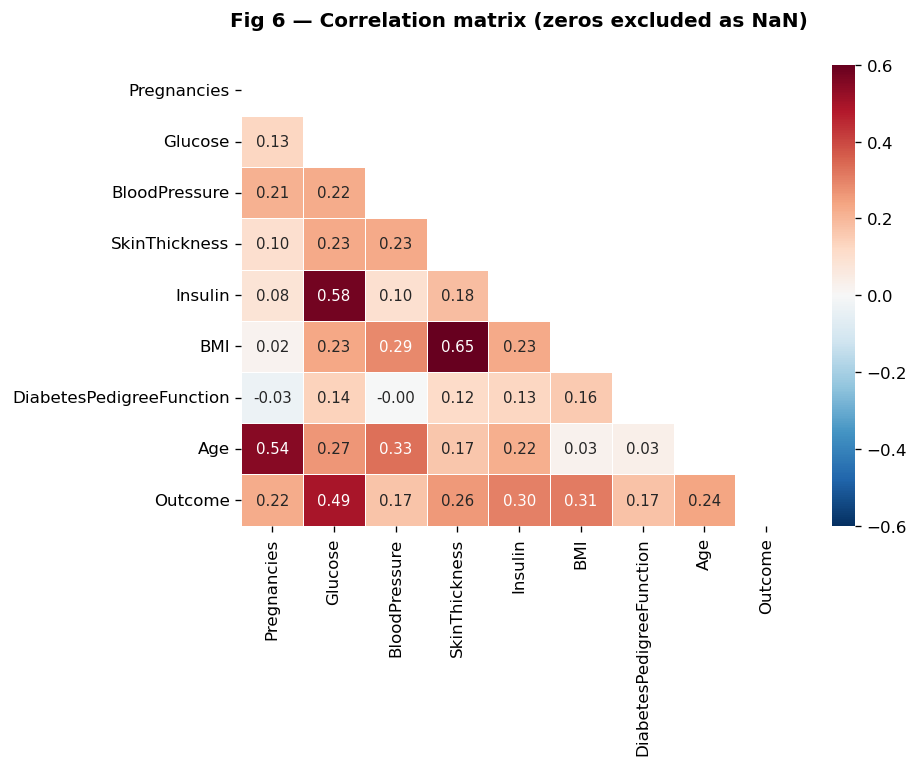

Correlations with Outcome (highest to lowest):
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [8]:
clean2 = df.drop(columns='age_group', errors='ignore').copy()
for c in ZERO_COLS:
    clean2.loc[clean2[c] == 0, c] = np.nan

corr = clean2.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, ax=ax,
            annot_kws={'size': 9}, vmin=-0.6, vmax=0.6)
ax.set_title('Fig 6 — Correlation matrix (zeros excluded as NaN)\n'
             ,
             fontweight='bold', pad=10)
plt.tight_layout(); plt.show()

print("Correlations with Outcome (highest to lowest):")
print(corr['Outcome'].drop('Outcome').sort_values(ascending=False).round(3))

The biggest correlation index for Outcome is Glucose, with a 0.49 correlation index, followed by BMI (0.31) and Insulin (0.30). Still, as the data has so many gaps (all zeros were eliminated from the analysis), this conclusion cannot be reached without the feeling that it is most likely incorrect.
